# Backbone sweep — predicted keypoint visualisation

For each of the 4 backbone variants (resnet18, resnet34, dino-v3-convnext-small,
dino-v3-vit-s16) we pick the **last** run from
`results/sweeps/benchmark_backbone/task_{1..4}/`, load its `last.ckpt` checkpoint,
and run inference on 5 fixed CrowdPose test images.

Each predicted keypoint is drawn as a circle:
- **border colour** — which person slot it belongs to (tab10 palette)
- **number inside** — joint type index (0 = left_shoulder … 13 = neck)

Rows are backbone variants; columns are the 5 example images.

In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

In [12]:
import json
from pathlib import Path

import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
import numpy as np
import torch
import torchvision.io as tvio

from src.data import CROWDPOSE_JOINT_NAMES
from src.data.data_module import resize_and_pad_to_square
from src.metrics import canonical_to_pixel
from src.utils import find_last_run, load_backbone_probe_module

# ── Paths ────────────────────────────────────────────────────────────────────
SWEEP_DIR  = Path("results/sweeps/benchmark_backbone")
IMG_DIR    = Path("data/crowdpose/images")

# 3 fixed test images
EXAMPLE_IMAGE_IDS = [106848, 103319, 107212]

# Inference settings
MAX_SIZE      = 128   # must match the training config (max_size: 128)
TOP_K_SLOTS   = 5     # how many slots to show per image
SCORE_THRESH  = 0.3   # minimum slot objectness score

JOINT_NAMES = {v: k for k, v in CROWDPOSE_JOINT_NAMES.items()}   # idx → name


In [3]:
# ── Discover the latest run per task ─────────────────────────────────────────
task_runs = find_last_run(SWEEP_DIR)   # {1: Path, 2: Path, 3: Path, 4: Path}

for tid, run_dir in sorted(task_runs.items()):
    overrides_path = run_dir / ".hydra" / "overrides.yaml"
    override_line  = overrides_path.read_text().strip().lstrip("- ")
    print(f"task {tid}: {override_line:35s}  →  {run_dir.name}")

task 1: backbone=resnet18                    →  20260517_101310
task 2: backbone=resnet34                    →  20260517_114830
task 3: backbone=dino-v3-convnext-small      →  20260517_132549
task 4: backbone=dino-v3-vit-s16             →  20260517_150502


In [13]:
# ── Load and preprocess the 5 example images ─────────────────────────────────
#
# Each image is:
#   1. loaded as uint8 [3, H, W]
#   2. converted to float [0, 1]
#   3. resized + padded to MAX_SIZE × MAX_SIZE square
#
# We keep both the padded tensor (model input) and a uint8 numpy copy (display).

padded_images: list[torch.Tensor] = []   # [3, MAX_SIZE, MAX_SIZE] float
display_images: list[np.ndarray]  = []   # [MAX_SIZE, MAX_SIZE, 3] uint8

for img_id in EXAMPLE_IMAGE_IDS:
    img_path = IMG_DIR / f"{img_id}.jpg"
    img_u8   = tvio.read_image(str(img_path))               # [3, H, W] uint8
    img_f    = img_u8.float() / 255.0
    padded, _ = resize_and_pad_to_square(img_f, MAX_SIZE)   # [3, 128, 128]
    padded_images.append(padded)
    display_images.append((padded.permute(1, 2, 0).numpy() * 255).astype(np.uint8))

print(f"Loaded {len(padded_images)} images, each padded to {MAX_SIZE}×{MAX_SIZE}")

Loaded 3 images, each padded to 128×128


In [14]:
# ── Load all 4 backbone models (loads checkpoints from disk) ─────────────────
#
# This cell is slow on first run (~30s total). Re-run to reload checkpoints.

modules: dict[int, torch.nn.Module] = {}
backbone_names: dict[int, str]      = {}
test_ap: dict[int, float]           = {}

for tid, run_dir in sorted(task_runs.items()):
    print(f"Loading task {tid} from {run_dir.name} …", end=" ", flush=True)
    module, cfg = load_backbone_probe_module(run_dir, ckpt_name="last.ckpt")
    modules[tid] = module

    # Human-readable backbone name from overrides.yaml
    overrides_line = (run_dir / ".hydra" / "overrides.yaml").read_text().strip().lstrip("- ")
    backbone_names[tid] = overrides_line.replace("backbone=", "")

    # Test AP from test_results.json (if it exists)
    results_path = run_dir / "test_results.json"
    if results_path.exists():
        with open(results_path) as f:
            metrics = json.load(f).get("metrics", {})
        test_ap[tid] = metrics.get("test/crowdpose/AP", float("nan"))
    else:
        test_ap[tid] = float("nan")

    print(f"done  (AP={test_ap[tid]:.4f})")

Loading task 1 from 20260517_101310 … loading annotations into memory...
Done (t=0.05s)
creating index...
index created!
loading annotations into memory...
Done (t=0.20s)
creating index...
index created!
done  (AP=0.0487)
Loading task 2 from 20260517_114830 … loading annotations into memory...
Done (t=0.05s)
creating index...
index created!
loading annotations into memory...
Done (t=0.20s)
creating index...
index created!
done  (AP=0.0499)
Loading task 3 from 20260517_132549 … 

Loading weights:   0%|          | 0/342 [00:00<?, ?it/s]

loading annotations into memory...
Done (t=0.05s)
creating index...
index created!
loading annotations into memory...
Done (t=0.21s)
creating index...
index created!
done  (AP=0.0083)
Loading task 4 from 20260517_150502 … 

Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

loading annotations into memory...
Done (t=0.05s)
creating index...
index created!
loading annotations into memory...
Done (t=0.20s)
creating index...
index created!
done  (AP=0.0376)


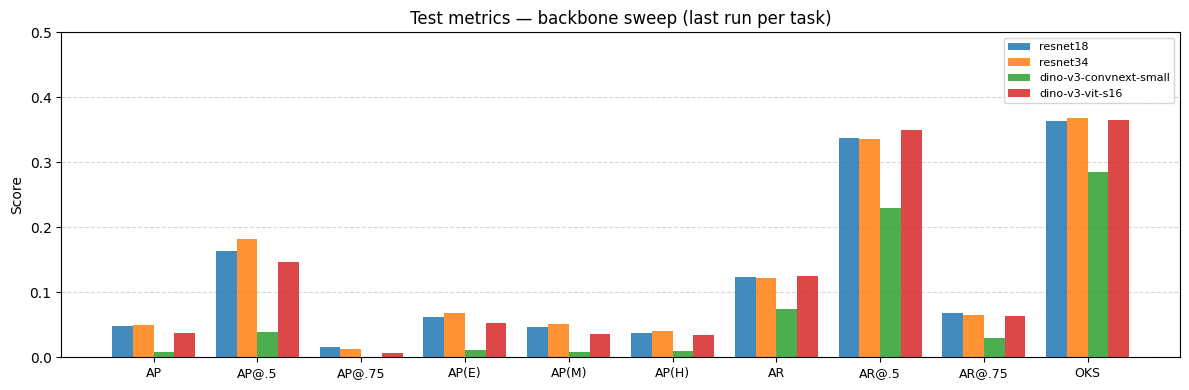

In [20]:
# ── Metrics bar plot ──────────────────────────────────────────────────────────
import pandas as pd

PLOT_METRICS = {
    "AP":    "test/crowdpose/AP",
    "AP@.5": "test/crowdpose/AP .5",
    "AP@.75":"test/crowdpose/AP .75",
    "AP(E)": "test/crowdpose/AP(E)",
    "AP(M)": "test/crowdpose/AP(M)",
    "AP(H)": "test/crowdpose/AP(H)",
    "AR":    "test/crowdpose/AR",
    "AR@.5": "test/crowdpose/AR .5",
    "AR@.75":"test/crowdpose/AR .75",
    "OKS":   "test/mean_oks",
}

rows = []
for tid, run_dir in sorted(task_runs.items()):
    results_path = run_dir / "test_results.json"
    if not results_path.exists():
        continue
    with open(results_path) as f:
        raw = json.load(f).get("metrics", {})
    row = {"backbone": backbone_names[tid]}
    for col, key in PLOT_METRICS.items():
        row[col] = raw.get(key, float("nan"))
    rows.append(row)

df = pd.DataFrame(rows).set_index("backbone")

x = np.arange(len(PLOT_METRICS))
width = 0.8 / len(df)
cmap = plt.colormaps["tab10"]

fig, ax = plt.subplots(figsize=(12, 4))
for i, (backbone, row) in enumerate(df.iterrows()):
    offset = (i - len(df) / 2 + 0.5) * width
    bars = ax.bar(x + offset, row.values, width, label=backbone, color=cmap(i), alpha=0.85)

ax.set_xticks(x)
ax.set_xticklabels(list(PLOT_METRICS.keys()), fontsize=9)
ax.set_ylabel("Score")
ax.set_title("Test metrics — backbone sweep (last run per task)")
ax.legend(fontsize=8, loc="upper right")
ax.set_ylim(0, 0.5)
ax.yaxis.grid(True, linestyle="--", alpha=0.5)
ax.set_axisbelow(True)
fig.tight_layout()
plt.show()


In [15]:
# ── Run inference ─────────────────────────────────────────────────────────────
#
# For each backbone, forward-pass all 5 images as a single batch.
# Outputs are kept as numpy for visualisation.
#
# predictions[tid][img_idx] = dict with keys:
#   kpts_pixel  [N, K, 2]  — pixel coords on the padded MAX_SIZE × MAX_SIZE image
#   scores      [N]        — slot objectness scores
#   kpt_scores  [N, K]     — per-keypoint scores

predictions: dict[int, list[dict]] = {}

with torch.no_grad():
    for tid, module in sorted(modules.items()):
        batch = torch.stack(padded_images)  # [5, 3, 128, 128]
        # _forward expects a dict with key "image"
        pred = module._forward({"image": batch})

        kpts_canonical = pred["keypoints"].cpu()        # [5, N, K, 2]
        scores_all     = pred["scores"].cpu()           # [5, N]
        kpt_scores_all = pred["keypoint_scores"].cpu()  # [5, N, K]

        B = kpts_canonical.shape[0]
        img_wh = torch.tensor([[MAX_SIZE, MAX_SIZE]], dtype=torch.float32).expand(B, -1)
        kpts_pixel_all = canonical_to_pixel(kpts_canonical, img_wh)  # [5, N, K, 2]

        predictions[tid] = [
            {
                "kpts_pixel": kpts_pixel_all[i].numpy(),
                "scores":     scores_all[i].numpy(),
                "kpt_scores": kpt_scores_all[i].numpy(),
            }
            for i in range(len(EXAMPLE_IMAGE_IDS))
        ]

print("Inference done.")

Inference done.


In [16]:
# ── Visualisation helper ──────────────────────────────────────────────────────

def plot_keypoints_with_slots(
    ax: plt.Axes,
    img_np: np.ndarray,
    kpts_pixel: np.ndarray,
    scores: np.ndarray,
    kpt_scores: np.ndarray,
    top_k: int = TOP_K_SLOTS,
    score_thresh: float = SCORE_THRESH,
    radius: float = 2.5,
) -> None:
    """Overlay predicted keypoints on *ax*.

    Args:
        ax:          matplotlib axes to draw on.
        img_np:      [H, W, 3] uint8 display image.
        kpts_pixel:  [N, K, 2] keypoints in pixel space (x, y).
        scores:      [N] slot objectness scores.
        kpt_scores:  [N, K] per-keypoint scores.
        top_k:       number of highest-scoring slots to display.
        score_thresh: minimum slot score; slots below this are skipped.
        radius:      circle radius in pixels.
    """
    ax.imshow(img_np, origin="upper")

    H, W = img_np.shape[:2]
    cmap  = plt.colormaps["tab10"]
    order = np.argsort(scores)[::-1][:top_k]

    # predict_visibility=False → kpt_scores all ≈ 0.5; skip per-keypoint filtering
    use_kpt_filter = kpt_scores.max() > 0.6

    for rank, slot_idx in enumerate(order):
        if scores[slot_idx] < score_thresh:
            continue
        slot_color = cmap(rank % 10)

        for k_idx in range(kpts_pixel.shape[1]):
            if use_kpt_filter and kpt_scores[slot_idx, k_idx] < 0.5:
                continue
            x, y = kpts_pixel[slot_idx, k_idx]
            if not (0 <= x < W and 0 <= y < H):
                continue
            circle = mpatches.Circle(
                (x, y), radius=radius,
                facecolor="white", edgecolor=slot_color,
                linewidth=1.0, alpha=0.9, zorder=2,
            )
            ax.add_patch(circle)
            ax.text(
                x, y, str(k_idx),
                ha="center", va="center",
                fontsize=3, color=slot_color, fontweight="bold", zorder=3,
            )

    ax.axis("off")


In [10]:
%matplotlib inline

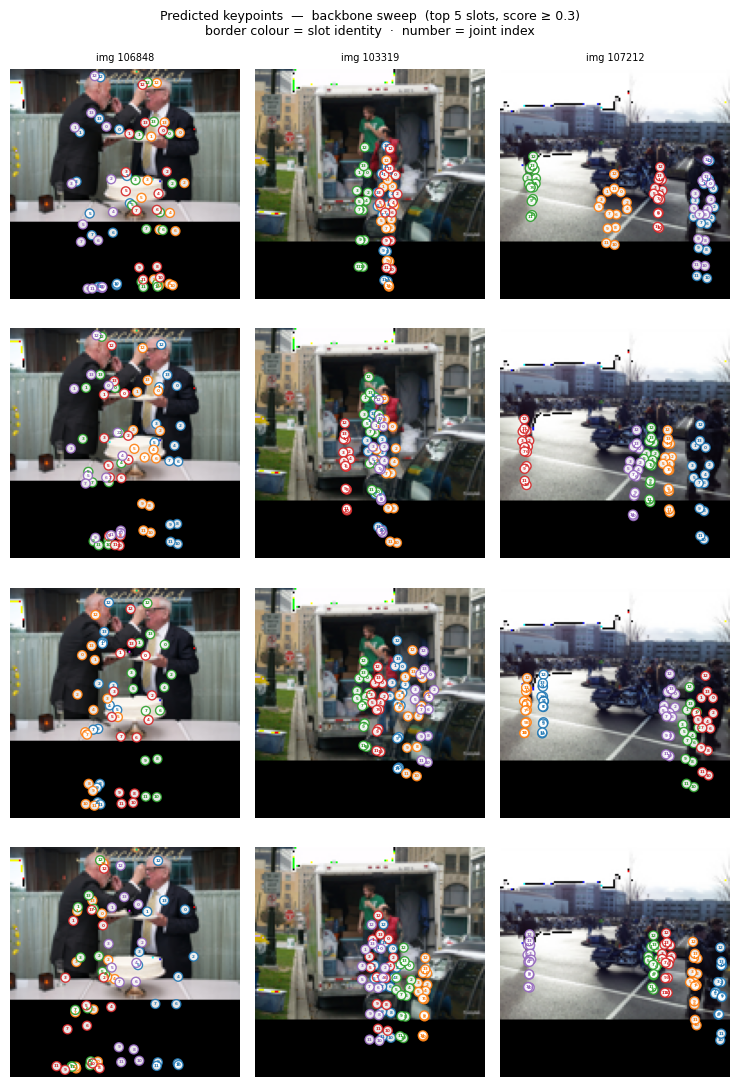

Joint index legend:
   0  left_shoulder
   1  right_shoulder
   2  left_elbow
   3  right_elbow
   4  left_wrist
   5  right_wrist
   6  left_hip
   7  right_hip
   8  left_knee
   9  right_knee
  10  left_ankle
  11  right_ankle
  12  head
  13  neck


In [17]:
# ── Display grid: 4 backbones × 5 images ─────────────────────────────────────

n_rows = len(task_runs)
n_cols = len(EXAMPLE_IMAGE_IDS)
fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * 2.5, n_rows * 2.8))

for row, tid in enumerate(sorted(task_runs)):
    backbone = backbone_names[tid]
    ap_val   = test_ap[tid]
    ap_str   = f"AP={ap_val:.3f}" if not np.isnan(ap_val) else "AP=n/a"

    for col, img_idx in enumerate(range(n_cols)):
        ax  = axes[row, col]
        pred = predictions[tid][img_idx]
        plot_keypoints_with_slots(
            ax,
            display_images[img_idx],
            pred["kpts_pixel"],
            pred["scores"],
            pred["kpt_scores"],
        )
        if col == 0:
            ax.set_ylabel(f"{backbone}\n{ap_str}", fontsize=8, labelpad=4)
        if row == 0:
            ax.set_title(f"img {EXAMPLE_IMAGE_IDS[img_idx]}", fontsize=7)

fig.suptitle(
    f"Predicted keypoints  —  backbone sweep  "
    f"(top {TOP_K_SLOTS} slots, score ≥ {SCORE_THRESH})\n"
    f"border colour = slot identity  ·  number = joint index",
    fontsize=9,
)
fig.tight_layout()
plt.show()

# Joint index legend
print("Joint index legend:")
for idx in range(14):
    print(f"  {idx:2d}  {JOINT_NAMES[idx]}")